# E8 · Is the assistant accurate and grounded? (live session)

PLAN §9, E8. Baseline: a keyword router. Stream C owns it. Parts:

1. **Intent accuracy** on the labelled questions (`data/e8_questions.yaml`), package classifier vs a keyword baseline.
2. **Grounded answers**: run the real pipeline (`anchorai.assistant.service.answer`) on a subset. *Calls the LLM.*
3. **Faithfulness**: cheap programmatic checks, then an LLM-as-judge. *Calls the LLM.*
4. **Latency**.
5. **Manual spot check** template.
6. **Ollama vs hosted** (only if a second endpoint is configured).
7. **Prompt variant**: the current grounded prompt against a stricter candidate on the same evidence. *Calls the LLM.*

**Cost.** Parts 1 and 4's classifier timing run offline (local embeddings). Parts 2, 3 and 6 call the configured
endpoint: about `N` answer calls plus `N` judge calls (default `N = 20`), plus the same again for each calibration
case. Set `N` in the first cell. The base URL and key are never printed here.

**Caveats to quote with the numbers.**

- The ~60 questions were written by an AI (Claude) from the intent descriptions, and the training examples in
  `intents.yaml` have the same authors, so intent accuracy is **optimistic**. Streams A and B wrote 24 held-out
  questions (HANDOFFS #14, #15) in `data/e8_questions.yaml` (`stream_a_questions`, `stream_b_questions`); the accuracy
  table reports each author separately and the held-out numbers are the ones to trust.
- An LLM judging answers is itself fallible and tends to favour its own wording. The judge here is calibrated on two known
  bad answers and checked by hand in part 5, and by default it is the same model that wrote the answer; set `JUDGE_MODEL`
  to a different one if you can.
- The evidence comes from the scenario-layer data, so "faithful" means *faithful to the evidence lines*, not *true of a
  real gym*.

In [1]:
import json
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES, DATA = Path("figures"), Path("results"), Path("data")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

N = 20                      # answers to generate and judge (parts 2-6)
SEED = 0
JUDGE_MODEL = None          # None: the configured LLM_MODEL

from anchorai.config import get_settings

settings = get_settings()
print("endpoint:", "set" if settings.llm_base_url else "(not set)", "| model:", settings.llm_model,
      "| key:", "set" if settings.llm_api_key else "(not set)")

spec = yaml.safe_load((DATA / "e8_questions.yaml").read_text())
rows = [dict(q, group=g) for g in ("questions", "stream_a_questions", "stream_b_questions") for q in spec[g]]
qs = pd.DataFrame(rows)


def ctx(value):
    # pandas turns a missing context into NaN, which is truthy; the classifier wants None.
    return value if isinstance(value, str) else None


print(len(qs), "questions;", qs["author"].value_counts().to_dict())
qs["intent"].value_counts().to_frame("questions").T

endpoint: set | model: claude-haiku-5-5 | key: set
86 questions; {'ai': 62, 'mokdy': 15, 'asiri': 9}


intent,unknown,member_actions,member_risk,graph_impact,list_members,compare_members,plan_summary,what_if_budget
questions,19,15,13,10,9,7,7,6


## 1. Intent accuracy

The package classifier (`get_classifier()`: sentence-embedding similarity to each intent's example centroid, a threshold
for `unknown`, and the member-slot rule) against a **keyword router** you can read in the next cell. The keyword router
gets the same slot extraction (member ids, amounts) so the comparison is about the intent decision.

In [2]:
from anchorai.assistant.classifier import UNKNOWN, get_classifier

t = time.perf_counter()
classifier = get_classifier()
print(f"classifier ready in {time.perf_counter() - t:.1f}s; intents:", [s.name for s in classifier.specs], "| threshold", classifier.threshold)
from anchorai.assistant.slots import extract_slots

INTENTS = [s.name for s in classifier.specs] + [UNKNOWN]
missing = sorted(set(qs["intent"]) - set(INTENTS))
if missing:
    print("WARNING: intents in the question set that the classifier does not know:", missing, "(they count as errors)")


def keyword_router(text, context_member_id=None):
    slots = extract_slots(text, classifier.instructors, classifier.classes)[0]
    n = len(slots.member_ids) or (1 if context_member_id else 0)
    t = text.lower()
    has = lambda *words: any(re.search(rf"\b{w}", t) for w in words)
    if has("budget", "spend", "what if") or slots.amount is not None:
        return "what_if_budget"
    if n >= 2 or (n == 1 and has("compare", "versus", "vs", "instead", "ahead")):
        return "compare_members"
    if slots.instructor_ids or slots.class_ids or has("affected", "instructor", "cancel", "cancelled"):
        return "graph_impact" if not n else "member_actions"
    if has("plan"):
        return "plan_summary"
    if n == 1:
        return "member_actions" if has("offer", "should", "do", "rule", "contact", "recommend", "action") else "member_risk"
    if has("top", "list", "most", "rank", "riskiest", "at risk", "high risk"):
        return "list_members"
    return UNKNOWN

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5047.53it/s]

classifier ready in 8.3s; intents: ['member_risk', 'member_actions', 'compare_members', 'graph_impact', 'list_members', 'plan_summary', 'what_if_budget'] | threshold 0.35


In [3]:
preds, lat = [], []
for q in qs.itertuples():
    t = time.perf_counter()
    p = classifier.classify(q.question, ctx(q.context_member_id))
    lat.append(time.perf_counter() - t)
    preds.append({"pred": p.intent, "score": p.score, "baseline": keyword_router(q.question, ctx(q.context_member_id))})
qs = qs.drop(columns=[c for c in ("pred", "score", "baseline") if c in qs]).join(pd.DataFrame(preds))
qs["correct"] = qs["pred"] == qs["intent"]
qs["baseline_correct"] = qs["baseline"] == qs["intent"]
print(f"classifier accuracy {qs['correct'].mean():.1%} | keyword baseline {qs['baseline_correct'].mean():.1%} | "
      f"classify latency median {np.median(lat) * 1000:.0f} ms, p95 {np.percentile(lat, 95) * 1000:.0f} ms")
qs.groupby("author")[["correct", "baseline_correct"]].agg(["mean", "size"]).round(3)

classifier accuracy 80.2% | keyword baseline 70.9% | classify latency median 2 ms, p95 2 ms


correct      baseline_correct     
          mean size             mean size
author                                   
ai       0.919   62            0.774   62
asiri    0.556    9            0.778    9
mokdy    0.467   15            0.400   15

In [4]:
from sklearn.metrics import classification_report, confusion_matrix

report = pd.DataFrame(classification_report(qs["intent"], qs["pred"], labels=INTENTS, output_dict=True, zero_division=0)).T
report_b = pd.DataFrame(classification_report(qs["intent"], qs["baseline"], labels=INTENTS, output_dict=True, zero_division=0)).T
per_intent = report.join(report_b, lsuffix="_classifier", rsuffix="_keyword")[
    ["precision_classifier", "recall_classifier", "f1-score_classifier", "f1-score_keyword", "support_classifier"]]
per_intent.round(2).to_csv(RES / "e8_intent_report.csv")
per_intent.round(2)

,precision_classifier,recall_classifier,f1-score_classifier,f1-score_keyword,support_classifier
member_risk,0.90,0.69,0.78,0.71,13.0
member_actions,0.79,0.73,0.76,0.64,15.0
compare_members,1.00,1.00,1.00,1.00,7.0
graph_impact,0.90,0.90,0.90,0.75,10.0
list_members,0.56,1.00,0.72,0.62,9.0
plan_summary,1.00,0.71,0.83,0.73,7.0
what_if_budget,1.00,1.00,1.00,0.92,6.0
unknown,0.72,0.68,0.70,0.58,19.0
accuracy,0.80,0.80,0.80,0.71,0.8
macro avg,0.86,0.84,0.84,0.75,86.0


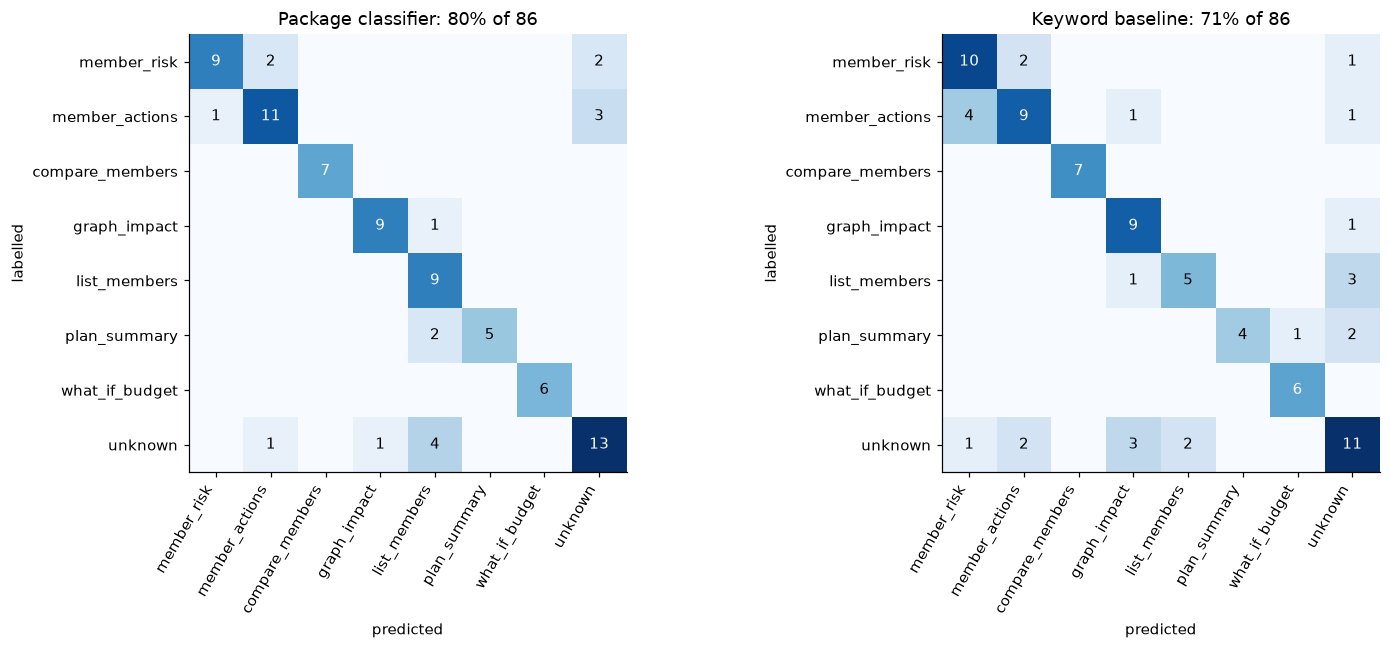

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, title in zip(axes, ["pred", "baseline"], ["Package classifier", "Keyword baseline"]):
    cm = confusion_matrix(qs["intent"], qs[col], labels=INTENTS)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(INTENTS)), INTENTS, rotation=60, ha="right")
    ax.set_yticks(range(len(INTENTS)), INTENTS)
    for i in range(len(INTENTS)):
        for j in range(len(INTENTS)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("predicted")
    ax.set_ylabel("labelled")
    ax.set_title(f"{title}: {(qs['intent'] == qs[col]).mean():.0%} of {len(qs)}")
fig.tight_layout()
fig.savefig(FIG / "e8_intent_confusion.png", bbox_inches="tight")

**Look at the errors.** Which are real classifier mistakes, which are ambiguous labels (the `notes` column flags boundary cases)?

In [6]:
errors = qs.loc[~qs["correct"], ["id", "question", "intent", "pred", "score", "baseline", "notes", "author"]]
errors.to_csv(RES / "e8_intent_errors.csv", index=False)
qs[["id", "author", "question", "intent", "pred", "score", "baseline", "correct", "baseline_correct"]].to_csv(RES / "e8_intent_predictions.csv", index=False)
errors

,id,question,intent,pred,score,baseline,notes,author
5,q06,how worried should we be about 1288?,member_risk,unknown,0.2663,unknown,"bare number, vague wording",ai
16,q17,Show the playbook for 1999,member_actions,unknown,0.1590,unknown,NaN,ai
30,q31,anyone hurt by the recent staff departure?,graph_impact,list_members,0.3710,unknown,no entity named,ai
44,q45,Which members are we ringing this week?,plan_summary,list_members,0.5738,unknown,boundary with list_members; plan call list,ai
58,q59,How do I add a new instructor?,unknown,graph_impact,0.5191,graph_impact,"app how-to, no tool",ai
63,a02,this member used to come every day before work...,member_risk,member_actions,0.4649,member_risk,asks how serious the drop is; borderline membe...,mokdy
64,a03,got 15 people to call and only time for 5 befo...,plan_summary,list_members,0.4046,unknown,priority within the call list; could be misrea...,mokdy
65,a04,member says she's switching to a gym closer to...,member_actions,member_risk,0.4079,member_risk,hard: the reason she gives is not in the data;...,mokdy
66,a05,why is this guy marked high risk when he liter...,member_risk,unknown,0.3388,member_risk,NaN,mokdy
67,a06,we ran that win-back offer last month and bare...,unknown,list_members,0.3725,unknown,hard: offer performance across members is not ...,mokdy


### Threshold sensitivity

The `unknown` decision is a single similarity threshold. Re-classify with the threshold off, then sweep it: too low
answers off-topic questions, too high refuses in-scope ones. (Same-author caveat applies: the threshold was tuned on the
training examples, not on this set.)

,threshold,accuracy,in_scope_refused,off_topic_answered
0,0.150,0.721,0.000,0.737
1,0.175,0.721,0.015,0.737
2,0.200,0.721,0.030,0.737
3,0.225,0.721,0.030,0.737
4,0.250,0.779,0.030,0.474
5,0.275,0.779,0.045,0.474
6,0.300,0.791,0.060,0.421
7,0.325,0.802,0.060,0.368
8,0.350,0.802,0.075,0.316
9,0.375,0.826,0.090,0.211


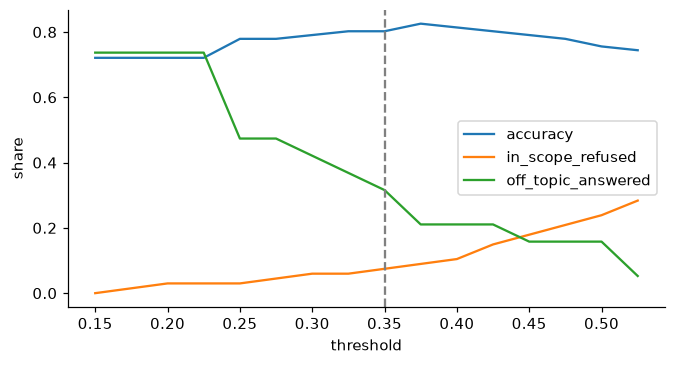

In [7]:
classifier.threshold, saved = -1.0, classifier.threshold
raw = [classifier.classify(q.question, ctx(q.context_member_id)) for q in qs.itertuples()]
classifier.threshold = saved
sweep = []
for th in np.arange(0.15, 0.55, 0.025):
    guess = [p.intent if p.score >= th else UNKNOWN for p in raw]
    truth = qs["intent"]
    sweep.append({
        "threshold": round(th, 3),
        "accuracy": float(np.mean([g == t for g, t in zip(guess, truth)])),
        "in_scope_refused": float(np.mean([g == UNKNOWN for g, t in zip(guess, truth) if t != UNKNOWN])),
        "off_topic_answered": float(np.mean([g != UNKNOWN for g, t in zip(guess, truth) if t == UNKNOWN])),
    })
sweep = pd.DataFrame(sweep)
sweep.round(3).to_csv(RES / "e8_threshold_sweep.csv", index=False)
ax = sweep.set_index("threshold").plot(figsize=(7, 3.5))
ax.axvline(saved, color="grey", ls="--")
ax.set_ylabel("share")
ax.figure.savefig(FIG / "e8_threshold_sweep.png", bbox_inches="tight")
sweep.round(3)

## 2. Grounded answers  (calls the LLM)

A stratified sample of `N` questions goes through the **real** pipeline: classifier, slots, deterministic tool,
grounded prompt, LLM. The session reads the app DB (plan, rosters) and writes nothing. Each answer keeps its evidence
lines so the judge can check against them. `role="manager"` so plan questions are answered.

**Look for:** `grounded=False` answers should be the "I don't know" / note replies; `llm_used=False` means the LLM
failed and the template fallback answered (those are skipped by the judge).

In [10]:
from sqlmodel import Session

from anchorai.assistant import llm
from anchorai.assistant.service import answer
from anchorai.db.session import get_engine

sample = pd.concat([
    qs[qs["intent"] == name].sample(min(n_in, max(1, round(N * n_in / len(qs)))), random_state=SEED)
    for name, n_in in qs["intent"].value_counts().items()
]).head(N)
print(len(sample), "questions:", sample["intent"].value_counts().to_dict())

llm_seconds = []


def timed_chat(messages):
    t = time.perf_counter()
    try:
        return llm.chat(messages)
    finally:
        llm_seconds.append(time.perf_counter() - t)


results = []
with Session(get_engine()) as session:
    for q in sample.itertuples():
        llm_seconds.clear()
        t = time.perf_counter()
        try:
            r = answer(session, q.question, ctx(q.context_member_id), role="manager", classifier=classifier, chat=timed_chat)
        except Exception as e:  # keep going: one failure should not lose the run
            results.append({"id": q.id, "error": type(e).__name__})
            continue
        results.append({
            "id": q.id, "question": q.question, "labelled": q.intent, "intent": r.intent, "tool": r.tool,
            "grounded": r.grounded, "llm_used": r.llm_used, "answer": r.answer,
            "evidence": json.dumps([e.model_dump() for e in r.evidence]),
            "total_s": time.perf_counter() - t, "llm_s": sum(llm_seconds),
        })
answers = pd.DataFrame(results)
answers.to_csv(RES / "e8_answers.csv", index=False)
print(answers[["grounded", "llm_used"]].value_counts().to_dict(), "| errors:", int(answers.get("error", pd.Series(dtype=object)).notna().sum()))
answers[["id", "question", "intent", "grounded", "llm_used", "answer"]]

20 questions: {'unknown': 4, 'member_actions': 3, 'member_risk': 3, 'graph_impact': 3, 'list_members': 2, 'compare_members': 2, 'plan_summary': 2, 'what_if_budget': 1}
{(True, True): 17, (False, False): 3} | errors: 0


,id,question,intent,grounded,llm_used,answer
0,q60,What is the capital of France?,unknown,False,False,I don't know based on the data I have.
1,b06,"what is the offer that is best for the gym, lo...",unknown,False,False,I don't know based on the data I have.
2,q58,"thanks, that helps",unknown,False,False,I don't know based on the data I have.
3,b05,what is the offer that most members like?,list_members,True,True,I don't know based on the data I have.
4,q14,wat should we do about M3333,member_actions,True,True,"- M3333 is on a 6-month contract, 5 months in,..."
5,b01,is a member sleeping dog?,member_actions,True,True,I don't know based on the data I have.
6,q12,What did the rules decide for member 2040?,member_actions,True,True,The rules blocked every offer for member 2040....
7,q03,M0231 churn risk breakdown please,member_risk,True,True,"M0231 has a 2% churn probability, which is low..."
8,q09,Tell me why M0014 is scored so high,member_risk,True,True,"- M0014 has a 74% churn probability, which is ..."
9,q05,why is this member flagged as risky?,member_risk,True,True,"M0008 is high risk, with an 89% churn probabil..."


## 3. Faithfulness

### 3a. Programmatic checks (free)

For each LLM answer: every sentence cites at least one evidence id; every cited id exists in the evidence; every number
or member id in the answer appears in the evidence. These catch invented figures and dangling citations; they cannot catch
an unsupported *reason* (that is what the judge is for). A citation after the full stop counts for that sentence, and the exact
"I don't know" reply needs none.

In [11]:
from anchorai.assistant.prompt import DONT_KNOW

CITE = re.compile(r"\[(E\d+)\]")
NUMBER = re.compile(r"M\d{4}|[<>]?\d+(?:[.,]\d+)*%?")


def norm(n):
    # "M0077", "member 77" and "4,000" vs "4000" are the same figure.
    n = n.lstrip("<>M").replace(",", "")
    return str(int(n)) if n.isdigit() else n


def split_sentences(text):
    # A citation after the full stop ("low risk. [E1]") belongs to that sentence.
    parts = re.split(r"\n+|(?<=[.!?\]])\s+(?=[A-Z])", text.strip())
    return [p.strip(" -\u2022") for p in parts if p.strip(" -\u2022")]


def static_checks(answer_text, evidence):
    ids = {e["id"] for e in evidence}
    evidence_text = " ".join(e["text"] for e in evidence)
    cited = CITE.findall(answer_text)
    plain = CITE.sub("", answer_text)
    # The exact refusal is the prompt's sanctioned reply, with nothing to cite.
    sentences = [] if answer_text.strip() == DONT_KNOW else split_sentences(answer_text)
    nums = {norm(n) for n in NUMBER.findall(plain)}
    known = {norm(n) for n in NUMBER.findall(evidence_text)}
    return {
        "sentences": len(sentences),
        # A lead-in ending in ":" introduces a cited list, so it needs no citation of its own.
        "uncited_sentences": sum(not CITE.search(s) and not s.endswith(":") for s in sentences),
        "dangling_citations": sorted(set(cited) - ids),
        "numbers_not_in_evidence": sorted(nums - known),
    }


llm_answers = answers[answers.get("llm_used", False) == True].copy()  # noqa: E712
checks = pd.DataFrame([static_checks(r.answer, json.loads(r.evidence)) for r in llm_answers.itertuples()], index=llm_answers["id"])
checks["ok"] = (checks["uncited_sentences"] == 0) & (checks["dangling_citations"].str.len() == 0) & (checks["numbers_not_in_evidence"].str.len() == 0)
checks.to_csv(RES / "e8_static_checks.csv")
print(f"{checks['ok'].mean():.0%} of {len(checks)} LLM answers pass all three checks")
checks

88% of 17 LLM answers pass all three checks


,sentences,uncited_sentences,dangling_citations,numbers_not_in_evidence,ok
id,,,,,
b05,0,0,[],[],True
q14,5,0,[],[],True
b01,0,0,[],[],True
q12,4,0,[],[],True
q03,5,0,[],[],True
q09,4,0,[],[],True
q05,7,0,[],[],True
q28,0,0,[],[],True
b07,3,0,[],[],True


### 3b. LLM-as-judge

The judge sees only the evidence lines and the answer (not the question's intent or how the answer was made), splits the
answer into sentences and labels each **supported / unsupported / contradicted**. The prompt is deliberately strict:
reasons, advice and ordering that the evidence does not state are *unsupported*, and a claim that data is missing when an
evidence line shows it is *contradicted*.

**First, calibrate on the two known problem answers** (`faithfulness_cases` in the question file), written from real
failures: the discount answer that invented "needs month-to-month terms, which the data doesn't show", and the
"Start with the check-in..." ordering. The judge must flag each *bad* answer and pass each *good* one before you trust it on
the sample. (This is 4 judge calls.)

In [12]:
from anchorai.assistant.llm import get_client

JUDGE_SYSTEM = (
    "You audit an assistant's answer against its evidence. Split the answer into sentences or bullets. "
    "For each, give a label:\n"
    "- supported: every claim is stated in an evidence line or follows from one directly;\n"
    "- unsupported: it contains a claim, number, name, reason, recommendation or ordering that no evidence line states;\n"
    "- contradicted: it conflicts with an evidence line, including saying data is missing that an evidence line shows.\n"
    "Be strict: reasons, causes, advice and what to do first are unsupported unless an evidence line says so. "
    "The reply 'I don't know based on the data I have.' is supported. "
    "Also list the evidence ids the sentence cites and whether those lines really support it.\n"
    'Reply with JSON only: {"sentences": [{"text": "...", "label": "supported|unsupported|contradicted", '
    '"cited": ["E1"], "citations_ok": true, "reason": "under 15 words"}]}'
)


def judge(answer_text, evidence_lines, model=None):
    user = "Evidence:\n" + "\n".join(evidence_lines) + "\n\nAnswer:\n" + answer_text
    reply = get_client().chat.completions.create(
        model=model or JUDGE_MODEL or settings.llm_model, temperature=0,
        messages=[{"role": "system", "content": JUDGE_SYSTEM}, {"role": "user", "content": user}],
    ).choices[0].message.content or ""
    reply = re.sub(r"^```(?:json)?|```$", "", reply.strip(), flags=re.MULTILINE).strip()
    try:
        return json.loads(reply)["sentences"]
    except (json.JSONDecodeError, KeyError, TypeError):
        return [{"text": reply[:200], "label": "judge_parse_error", "cited": [], "citations_ok": False, "reason": "unparseable judge reply"}]


def evidence_lines(evidence):
    return [f"[{e['id']}] {e['text']}" for e in evidence]

In [13]:
calibration = []
for case in spec["faithfulness_cases"]:
    for kind in ("bad_answer", "good_answer"):
        verdict = judge(case[kind], case["evidence"])
        calibration.append({"case": case["id"], "answer": kind, **{k: sum(s["label"] == k for s in verdict) for k in ("supported", "unsupported", "contradicted")},
                            "flagged": [s["text"][:70] for s in verdict if s["label"] != "supported"]})
        print(case["id"], kind, "| static:", static_checks(case[kind], [{"id": l[1:3], "text": l} for l in case["evidence"]]))
calibration = pd.DataFrame(calibration)
calibration.to_csv(RES / "e8_judge_calibration.csv", index=False)
calibration

f01 bad_answer | static: {'sentences': 1, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}
f01 good_answer | static: {'sentences': 3, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}
f02 bad_answer | static: {'sentences': 1, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}
f02 good_answer | static: {'sentences': 1, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}


,case,answer,supported,unsupported,contradicted,flagged
0,f01,bad_answer,0,1,0,[The discounted month is blocked by G03 becaus...
1,f01,good_answer,3,0,0,[]
2,f02,bad_answer,0,1,0,[Start with the check-in message by SMS to reb...
3,f02,good_answer,1,0,0,[]


**Expected:** both `bad_answer` rows flag at least one sentence (`unsupported`/`contradicted`); both `good_answer` rows flag
none. If not, tighten `JUDGE_SYSTEM` before going on. Note what the case file says the judge should catch (`expect_bad`).

In [14]:
verdicts = []
for r in llm_answers.itertuples():
    for s in judge(r.answer, evidence_lines(json.loads(r.evidence))):
        verdicts.append({"id": r.id, "intent": r.intent, "sentence": s["text"], "label": s["label"],
                         "citations_ok": s.get("citations_ok"), "reason": s.get("reason", "")})
verdicts = pd.DataFrame(verdicts)
verdicts.to_csv(RES / "e8_judge_sentences.csv", index=False)

per_answer = verdicts.groupby("id").agg(
    sentences=("label", "size"), supported=("label", lambda s: (s == "supported").sum()),
    flagged=("label", lambda s: (s != "supported").sum()))
per_answer["fully_supported"] = per_answer["flagged"] == 0
faith = pd.DataFrame({
    "sentences": [len(verdicts)],
    "supported_share": [(verdicts["label"] == "supported").mean()],
    "unsupported_share": [(verdicts["label"] == "unsupported").mean()],
    "contradicted_share": [(verdicts["label"] == "contradicted").mean()],
    "answers": [len(per_answer)],
    "fully_supported_answers": [per_answer["fully_supported"].mean()],
    "citations_ok_share": [verdicts["citations_ok"].astype(bool).mean()],
}).round(3)
faith.to_csv(RES / "e8_faithfulness.csv", index=False)
faith

,sentences,supported_share,unsupported_share,contradicted_share,answers,fully_supported_answers,citations_ok_share
0,80,0.962,0.038,0.0,17,0.882,0.962


In [15]:
verdicts[verdicts["label"] != "supported"][["id", "intent", "label", "sentence", "reason"]]

,id,intent,label,sentence,reason
28,b07,graph_impact,unsupported,"Based on this data, Maya Chen is the only inst...",No evidence says she is the only instructor or...
38,q40,list_members,unsupported,All ten listed members are above 99% churn pro...,"Probability and segment match E2-E11, but 'so ..."
39,q40,list_members,unsupported,Start at the top of this ranked list [E1].,"E1 shows a top-10 list by churn probability, b..."


,mean,size
intent,,
compare_members,1.00,13
graph_impact,0.91,11
list_members,0.92,24
member_actions,1.00,10
member_risk,1.00,16
plan_summary,1.00,3
what_if_budget,1.00,3


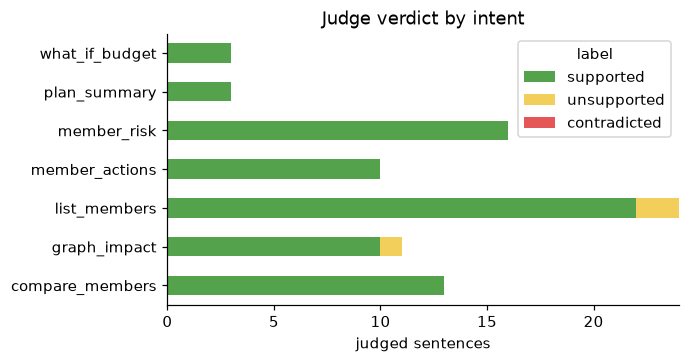

In [16]:
by_intent = verdicts.assign(ok=verdicts["label"] == "supported").groupby("intent")["ok"].agg(["mean", "size"]).round(2)
fig, ax = plt.subplots(figsize=(6, 3.2))
counts = verdicts.groupby(["intent", "label"]).size().unstack(fill_value=0).reindex(columns=["supported", "unsupported", "contradicted"], fill_value=0)
counts.plot.barh(stacked=True, ax=ax, color=["#54a24b", "#f2cf5b", "#e45756"])
ax.set_xlabel("judged sentences")
ax.set_ylabel("")
ax.set_title("Judge verdict by intent")
fig.savefig(FIG / "e8_faithfulness.png", bbox_inches="tight")
by_intent

## 4. Latency

End-to-end per question (classify + tool + LLM) and the LLM call alone. Template and note replies (no LLM) are in the
first number only. Local model on a laptop and a hosted API will differ widely; say which one produced these.

,n,median_s,p95_s,max_s
end-to-end,20,4.52,7.11,8.17
LLM call only,17,4.58,6.25,8.14


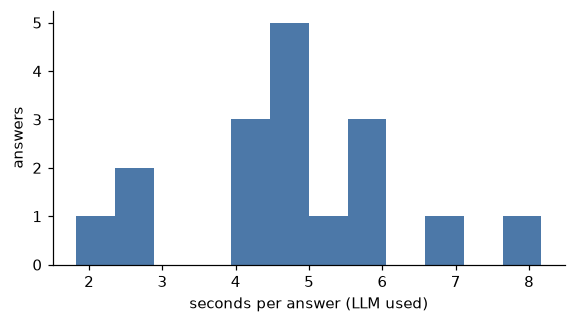

In [17]:
lat = answers.dropna(subset=["total_s"])
latency = pd.DataFrame({
    "n": [len(lat), int(lat["llm_used"].sum())],
    "median_s": [lat["total_s"].median(), lat.loc[lat["llm_used"], "llm_s"].median()],
    "p95_s": [lat["total_s"].quantile(0.95), lat.loc[lat["llm_used"], "llm_s"].quantile(0.95)],
    "max_s": [lat["total_s"].max(), lat.loc[lat["llm_used"], "llm_s"].max()],
}, index=["end-to-end", "LLM call only"]).round(2)
latency.to_csv(RES / "e8_latency.csv")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(lat.loc[lat["llm_used"], "total_s"], bins=12, color="#4c78a8")
ax.set_xlabel("seconds per answer (LLM used)")
ax.set_ylabel("answers")
fig.savefig(FIG / "e8_latency.png", bbox_inches="tight")
latency

## 5. Manual spot check

The judge is a model; a human has the last word. Reads 15 sampled answers beside their evidence, fills the empty columns
in `results/e8_spot_check.csv` (open it in a spreadsheet), then the last cell summarises. Two people should each fill one
column set if possible; agree on disagreements.

- `faithful`: y / n (every claim backed by the evidence lines?)
- `correct`: y / n (does it answer what was asked?)
- `useful`: 1-5
- `judge_agrees`: y / n (compare with `judge_flagged`)
- `notes`

In [18]:
flagged = verdicts[verdicts["label"] != "supported"].groupby("id").size()
spot = llm_answers.sample(min(15, len(llm_answers)), random_state=SEED)[["id", "question", "answer", "evidence"]].copy()
spot["evidence"] = spot["evidence"].map(lambda e: " | ".join(f"[{x['id']}] {x['text']}" for x in json.loads(e)))
spot["judge_flagged"] = spot["id"].map(flagged).fillna(0).astype(int)
for col in ("faithful", "correct", "useful", "judge_agrees", "notes"):
    spot[col] = ""
path = RES / "e8_spot_check.csv"
if path.exists() and pd.read_csv(path)["faithful"].notna().any():
    print("existing spot-check file has entries; not overwriting")
else:
    spot.to_csv(path, index=False)
    print("template written to", path)

existing spot-check file has entries; not overwriting


In [30]:
filled = pd.read_csv(RES / "e8_spot_check.csv")
done = filled[filled["faithful"].isin(["y", "n"])]
if done.empty:
    print("nothing filled in yet")
else:
    print(f"{len(done)} checked | faithful {done['faithful'].eq('y').mean():.0%} | correct {done['correct'].eq('y').mean():.0%} | "
          f"mean usefulness {pd.to_numeric(done['useful'], errors='coerce').mean():.1f} | judge agrees {done['judge_agrees'].eq('y').mean():.0%}")

15 checked | faithful 87% | correct 80% | mean usefulness 3.7 | judge agrees 100%


## 6. Ollama vs hosted model

Runs only when a **second** OpenAI-compatible endpoint is configured through the environment (not committed):

```
E8_ALT_BASE_URL=...   E8_ALT_API_KEY=...   E8_ALT_MODEL=...
```

It replays the *same evidence* from part 2 through the alternative model with the package's grounded prompt
(`anchorai.assistant.prompt.build_messages`), then judges both sets with the same judge, and compares latency and
faithfulness. The model configured in `.env` is "primary" (say in the report which of Ollama/hosted that is).
Evidence is held fixed so only the phrasing model differs.

In [28]:
from openai import OpenAI

from anchorai.assistant.prompt import build_messages
from anchorai.assistant.tools import Evidence

alt = {k: os.environ.get(f"E8_ALT_{k}") for k in ("BASE_URL", "API_KEY", "MODEL")}
if not all(alt.values()):
    print("No alternative endpoint configured (set E8_ALT_BASE_URL, E8_ALT_API_KEY, E8_ALT_MODEL); skipping part 6.")
else:
    alt_client = OpenAI(base_url=alt["BASE_URL"], api_key=alt["API_KEY"], timeout=settings.llm_timeout_seconds, max_retries=1)
    alt_rows = []
    for r in llm_answers.itertuples():
        evid = [Evidence(**e) for e in json.loads(r.evidence)]
        t = time.perf_counter()
        text = alt_client.chat.completions.create(
            model=alt["MODEL"], temperature=settings.llm_temperature, messages=build_messages(r.question, evid),
        ).choices[0].message.content or ""
        alt_rows.append({"id": r.id, "answer": text, "evidence": r.evidence, "llm_s": time.perf_counter() - t})
    alt_answers = pd.DataFrame(alt_rows)
    alt_answers.to_csv(RES / "e8_alt_answers.csv", index=False)

    def summarise(frame, name, model):
        v = [s["label"] for r in frame.itertuples() for s in judge(r.answer, evidence_lines(json.loads(r.evidence)))]
        st = [static_checks(r.answer, json.loads(r.evidence)) for r in frame.itertuples()]
        return {"model": name, "answers": len(frame), "median_llm_s": frame["llm_s"].median(), "p95_llm_s": frame["llm_s"].quantile(0.95),
                "supported_share": np.mean([x == "supported" for x in v]),
                "static_ok": np.mean([not s["uncited_sentences"] and not s["dangling_citations"] and not s["numbers_not_in_evidence"] for s in st])}

    comparison = pd.DataFrame([
        summarise(llm_answers, f"primary ({settings.llm_model})", None),
        summarise(alt_answers, f"alternative ({alt['MODEL']})", None),
    ]).round(3)
    comparison.to_csv(RES / "e8_model_comparison.csv", index=False)
    print(comparison.to_string(index=False))

                     model  answers  median_llm_s  p95_llm_s  supported_share  static_ok
primary (claude-haiku-5-5)       17         4.575      6.248            0.951      0.882
  alternative (qwen2.5:7b)       17         0.226      0.829            0.951      0.706


## 7. Prompt variant  (calls the LLM)

Finding 9 asks for two prompt changes: cite every sentence, including the first, and add no advice or remarks about the
data that the evidence lines do not state. This part replays the **same evidence** from part 2 through the current
prompt and a candidate, then runs the free static checks and the judge on both. Only the system prompt differs.

**Cost:** 13 answer calls and 13 judge calls per prompt (52 in all for 13 answers). Set `RERUN_CURRENT = False` to reuse the
saved part 2 answers and judge verdicts for the current prompt instead (26 calls), at the price of comparing across runs,
which finding 3 shows can swing a lot.

**Fresh kernel:** run cell 1, the next cell (it loads the saved part 2 answers), then cells 14 and 16, then the rest of this part.
The summary and side-by-side cells read the saved replies and verdicts, so after cells 1 and 14 they rerun with no LLM calls.

The candidate won and is now `prompt.SYSTEM`; `CURRENT` below keeps the earlier prompt so the comparison can be rerun.


In [21]:
if "llm_answers" not in globals():
    answers = pd.read_csv(RES / "e8_answers.csv")
    llm_answers = answers[answers["llm_used"] == True].copy()  # noqa: E712
print(len(llm_answers), "answers with evidence to replay")

17 answers with evidence to replay


In [22]:
from anchorai.assistant import llm, prompt
from anchorai.assistant.prompt import build_messages
from anchorai.assistant.tools import Evidence

RERUN_CURRENT = True

# The prompt as it was before this test; prompt.SYSTEM is the candidate, adopted after the 2026-10-17 run.
CURRENT = f"""You are AnchorAI's assistant for gym staff, in a chat.
Earlier messages only tell you what the user is referring to ("they", "that offer").
Answer ONLY from the evidence lines in the latest message. Each line starts with an id such as [E1].
After each sentence or bullet, cite the ids it is based on, e.g. [E1][E3].
If the evidence does not answer the question, reply exactly: {prompt.DONT_KNOW}
Never invent numbers, names, offers or reasons that are not in the evidence.
Use plain English, at most 80 words (a list of members may take one bullet each). A short "- " bullet list is fine for several items.
No tables or headings."""
CANDIDATE = prompt.SYSTEM
assert CANDIDATE != CURRENT
print(CANDIDATE)


def replay(system):
    rows = []
    for r in llm_answers.itertuples():
        messages = build_messages(r.question, [Evidence(**e) for e in json.loads(r.evidence)])
        messages[0] = {"role": "system", "content": system}
        t = time.perf_counter()
        text = llm.chat(messages).strip() or prompt.DONT_KNOW
        rows.append({"id": r.id, "question": r.question, "intent": r.intent, "answer": text,
                     "evidence": r.evidence, "llm_s": time.perf_counter() - t})
    return pd.DataFrame(rows)


runs = {"candidate": replay(CANDIDATE)}
runs["current"] = replay(CURRENT) if RERUN_CURRENT else llm_answers[["id", "question", "intent", "answer", "evidence", "llm_s"]]
pd.concat([f.assign(prompt=name) for name, f in runs.items()]).to_csv(RES / "e8_prompt_variant_answers.csv", index=False)

You are AnchorAI's assistant for gym staff, in a chat.
Earlier messages only tell you what the user is referring to ("they", "that offer").
Answer ONLY from the evidence lines in the latest message. Each line starts with an id such as [E1].
End every sentence and bullet, including the first, with the ids it is based on, e.g. [E1][E3].
If the evidence does not answer the question, reply exactly: I don't know based on the data I have.
Never invent numbers, names, offers or reasons that are not in the evidence.
Do not add advice, an order to act in, or remarks about what the evidence does or does not show, unless an evidence line says it.
Use plain English, at most 80 words (a list of members may take one bullet each). A short "- " bullet list is fine for several items.
No tables or headings.


In [23]:
variant_verdicts = []
for name, frame in runs.items():
    if name == "current" and not RERUN_CURRENT:
        saved = pd.read_csv(RES / "e8_judge_sentences.csv")
        variant_verdicts += [{"prompt": name, "id": s.id, "sentence": s.sentence, "label": s.label, "reason": s.reason}
                             for s in saved.itertuples()]
        continue
    for r in frame.itertuples():
        for s in judge(r.answer, evidence_lines(json.loads(r.evidence))):
            variant_verdicts.append({"prompt": name, "id": r.id, "sentence": s["text"], "label": s["label"], "reason": s.get("reason", "")})
variant_verdicts = pd.DataFrame(variant_verdicts)
variant_verdicts.to_csv(RES / "e8_prompt_variant_judge.csv", index=False)



In [24]:
# Free: reads the saved replies and verdicts, so it reruns without LLM calls.
from anchorai.assistant import prompt

replies = pd.read_csv(RES / "e8_prompt_variant_answers.csv")
runs = {name: replies[replies["prompt"] == name] for name in ("current", "candidate")}
variant_verdicts = pd.read_csv(RES / "e8_prompt_variant_judge.csv")
def summary(name, frame):
    st = pd.DataFrame([static_checks(r.answer, json.loads(r.evidence)) for r in frame.itertuples()])
    v = variant_verdicts[variant_verdicts["prompt"] == name]
    fully = v.groupby("id")["label"].apply(lambda s: (s == "supported").all())
    words = frame["answer"].map(lambda a: len(CITE.sub("", a).split()))
    return {
        "prompt": name, "answers": len(frame),
        "static_ok": int(((st["uncited_sentences"] == 0) & (st["dangling_citations"].str.len() == 0)
                          & (st["numbers_not_in_evidence"].str.len() == 0)).sum()),
        "uncited_sentences": int(st["uncited_sentences"].sum()),
        "numbers_not_in_evidence": int(st["numbers_not_in_evidence"].str.len().sum()),
        "dont_know": int((frame["answer"] == prompt.DONT_KNOW).sum()),
        "judged_sentences": len(v), "supported_share": round((v["label"] == "supported").mean(), 3),
        "fully_supported_answers": int(fully.sum()), "median_words": float(words.median()),
    }


variant = pd.DataFrame([summary(name, frame) for name, frame in runs.items()]).set_index("prompt")
variant.to_csv(RES / "e8_prompt_variant.csv")
variant

,answers,static_ok,uncited_sentences,numbers_not_in_evidence,dont_know,judged_sentences,supported_share,fully_supported_answers,median_words
prompt,,,,,,,,,
current,17,9,11,1,3,93,0.892,9,54.0
candidate,17,17,0,0,4,74,0.973,15,38.0


**Look for:** the candidate should have fewer uncited sentences and flagged sentences without more "I don't know"
replies or answers too short to be useful. Read the pairs below side by side, especially q08, q27, q35 and q40 (the answers flagged in parts 3 and 5).

In [25]:
pairs = runs["current"][["id", "answer"]].merge(runs["candidate"][["id", "answer"]], on="id", suffixes=("_current", "_candidate"))
flags = variant_verdicts[variant_verdicts["label"] != "supported"].groupby(["prompt", "id"]).size().unstack(0, fill_value=0)
pairs = pairs.join(flags.add_prefix("flagged_"), on="id").fillna({"flagged_current": 0, "flagged_candidate": 0})
with pd.option_context("display.max_colwidth", None):
    display(pairs.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left"}))

,id,answer_current,answer_candidate,flagged_candidate,flagged_current
0,b05,I don't know based on the data I have.,I don't know based on the data I have.,0.000000,1.000000
1,q14,"- No offer can be made to M3333 right now. The playbook proposes none [E7], and three offers are blocked [E4][E5][E6]. - The 20% off month is for month-to-month members only, and M3333 is on a 6-month contract [E1][E2]. - Free personal training and the bring-a-friend pass are blocked by the rule against spending paid offers on low-risk members [E3]. - M3333 is not in the plan for the week of 2026-10-12 [E8]. - The data does not give a next step for this member.",I don't know based on the data I have.,0.000000,0.000000
2,b01,I don't know based on the data I have.,I don't know based on the data I have.,0.000000,0.000000
3,q12,"- The rules classed member 2040 as a social member, since they joined through a friend. [E4] - All offers were blocked by the contact cap guardrail, G01. [E2][E5] - Three paid offers were also blocked under guardrail G04, which stops paid offers for low-risk members: Free personal training session, Bring-a-friend class pass, and One month at 20% off. [E3][E6][E7][E8] - Member 2040 is not in the plan for the week of 2026-10-12. [E9]","- All offers are blocked by rule G01, which limits contact to the 30-day cap (default once). [E2][E5] - Three paid offers are blocked by rule G04, which says not to spend paid offers on low-risk members: Free personal training session, Bring-a-friend class pass, and One month at 20% off. [E3][E6][E7][E8] - Rule D06 concludes the member is social, because they joined through a friend, so social offers fit. [E4] - The member is not in the plan for the week of 2026-10-12. [E9]",0.000000,0.000000
4,q03,"M0231 has a 2% churn probability, which is low risk, and is in the 'Established solo trainers' segment [E1]. Risk drivers: - Months as a member raises risk [E3] - Age lowers risk [E4] - Change in weekly visits (this month vs lifetime) lowers risk [E5] Profile: 6-month contract, 1 month as a member, 2.2 visits/week this month vs 2.0 usual, no group classes [E2].","M0231 has a 2% churn probability, which is low risk, in the 'Established solo trainers' segment [E1]. - Months as a member raises risk [E3] - Age lowers risk [E4] - Change in weekly visits (this month vs lifetime) lowers risk [E5] Profile: 6-month contract, 1 month as a member, 2.2 visits/week this month versus 2.0 usual, and no group classes [E2]. M0231 is not in the plan for the week of 2026-10-12 [E6].",0.000000,0.000000
5,q09,"M0014 has a 74% churn probability, which is high risk. [E1] The main drivers are months as a member, age, and visits per week this month, each marked as raising risk. [E3][E4][E5] The member has been a member for 1 month and is on a month-to-month contract. [E2] Visits were 0.0 per week this month, the same as their usual rate. [E2] The data doesn't show how much each driver adds to the score.","- M0014 has a 74% churn probability, which is rated high risk. [E1] - The main risk drivers are months as a member, age, and visits per week this month, and each one raises risk. [E3][E4][E5] - The member has been a member for 1 month, is on a month-to-month contract, and attends group classes. [E2] - Visits were 0.0 per week this month, the same as the usual 0.0. [E2]",1.000000,1.000000
6,q05,"M0008 is flagged because its churn probability is 89%, a high-risk level, and the member is in the ""New and slipping"" segment [E1]. Three drivers raise the risk: months as a member [E3], extra spend per month [E4], and months left on contract [E5]. The profile shows a month-to-month contract, 0 months as a member, 1.0 visits per week this month versus 1.2 usually, and no group classes [E2]. The member is also not in the plan for the week of 2026-10-12 [E6].","M0008 is flagged as high risk, with an 89% churn probability in the ""New and slipping"" segment. [E1] The model lists these as factors that raise the risk: [E3][E4][E5] - Months as

## 8. Findings

From the run on 2026-10-20 (model `claude-haiku-5-5`, hosted), with the adopted prompt (part 7), Stream B's planner and
demo week in the app DB (`anchorai db reset`), the budget and staff-hours what-if, and the held-out questions of Streams A and B (part 1 rerun on 2026-10-23).
The spot check (part 5) was filled by Claude Code and checked by the owner, so it is not an independent human rating.

1. **Intent accuracy: 80.2% vs 70.9%** for the keyword baseline on 86 questions (macro F1 0.84 vs 0.75), but the three
   authors differ sharply:

   | questions | n | classifier | keyword baseline |
   |---|---|---|---|
   | AI-written (`ai`) | 62 | 91.9% | 77.4% |
   | Stream A, held out (`mokdy`) | 15 | 46.7% | 40.0% |
   | Stream B, held out (`asiri`) | 9 | 55.6% | 77.8% |
   | both held-out sets | 24 | 50.0% | 54.2% |

   On the 24 held-out questions the classifier is no better than the keyword router (12 of 24 vs 13 of 24). A's questions
   are long, chatty and indirect ("is that bad enough to reach out yet?"), and the classifier misses 8 of 15: it refuses
   three in-scope ones (a05, a08, a15), answers two off-topic ones it should refuse (a06, a09), and mixes up the rest
   between neighbouring intents (a02, a03, a04). B's misses are mostly out-of-scope questions
   it answers instead of refusing ("does this member attend PT sessions?", "what is the offer that most members like?",
   "which club has the highest impact if closed?"). With 24 questions the interval is wide, but the direction is clear:
   the 91.9% on the AI-written set (whose authors also wrote the training examples, and on which the 0.35 threshold was
   chosen) is optimistic, and the held-out 50.0% is the number to trust. The 5 AI-set misses are the boundary and
   bare-number cases of earlier runs ("how worried should we be about 1288?", "Show the playbook for 1999", "anyone hurt by
   the recent staff departure?", "which members are we ringing this week?", an app how-to). The 3 staff-hours examples
   added to `what_if_budget` for the what-if moved the AI-set score from 90.3% to 91.9%. Rerun offline on 2026-10-23
   with A's 15 questions added.
2. **Threshold:** with the off-topic held-out questions in, 32% of off-topic questions are answered at the 0.35 threshold
   (74% below 0.25). Raising it to 0.45 cuts that to 16% but refuses 18% of in-scope questions. Accuracy peaks at
   0.375 (82.6%).
3. **Grounding:** of 20 sampled questions, 17 went to the LLM; the 3 off-topic ones got the fixed "I don't know". Plan and
   what-if questions now answer from B's approved demo plan and planner. No answer used a number or member id missing from
   the evidence, and no citation pointed at a missing line. 15 of 17 answers pass every static check (88%; 8 of 13 on
   2026-10-17 with the old prompt): q40 has one uncited sentence and q25 three, each inside a bullet that ends with a
   citation. 3 answers are "I don't know": rightly for b01 ("is a member sleeping dog?") and the misrouted b05, wrongly for
   q28, whose evidence answers it. q28 was refused in both of the last two runs but answered in both part 7 replays, so it
   is run-to-run variation, not a fixed failure.
4. **Judge calibration:** the judge flagged both known bad answers and nothing in the two good ones.
5. **Judge on the sample:** 96.2% of 80 sentences supported, 3.8% unsupported, none contradicted; 15 of 17 answers (88.2%)
   fully supported (76.9% on 2026-10-17). The 3 flagged sentences are "Maya Chen is the only instructor listed, so she has
   the highest impact" (b07, a ranking the tool doesn't do) and q40's "so they are the ones to call" and "Start at the top
   of this ranked list".
6. **Spot check (15 answers):** 13 faithful (87%), 12 answer the question (80%), mean usefulness 3.7 / 5, and the judge
   agrees on all 15. Unfaithful: b07 (the ranking above) and q40 (outreach advice, as in every run: the question asks for
   advice, and the prompt rule against it does not fully hold). Not answered: q28's refusal, b07, and q53, where the
   what-if read "Is another $1,500 worth it?" as a $1,500 budget and reported no change. That was a slot bug, fixed after
   this run (`e48c01d`: "another", "extra" and "more" now add to the current limit), so q53 is the one answer here that the
   code no longer gives.
7. **Driver wording** stays fixed: q05, q03 and q09 read the signed visit change correctly.
8. **Latency:** median 4.5 s end to end (p95 7.1 s, max 8.2 s) over 20 questions; the LLM call is median 4.6 s (p95 6.3 s)
   over the 17 that used it. That is slower than on 2026-10-17 (2.9 s) on the same hosted model, so it reflects the endpoint
   on the day more than the code; the what-if tool adds about 2 s of planning (two exact solves). Classification takes about
   2 ms. A local model is compared in finding 10.
9. **Prompt variant (part 7), adopted.** Same evidence, both prompts regenerated and judged in one session, two runs:

   | | 2026-10-17, old | new | 2026-10-20, old | new |
   |---|---|---|---|---|
   | answers | 13 | 13 | 17 | 17 |
   | pass every static check | 4 | 11 | 9 | 17 |
   | uncited sentences | 9 | 4 | 11 | 0 |
   | judged sentences supported | 95.5% | 95.5% | 89.2% | 97.3% |
   | fully supported answers | 9 | 10 | 9 | 15 |
   | "I don't know" replies | 0 | 0 | 3 | 4 |
   | median words | 57 | 61 | 54 | 38 |

   The new prompt cites every sentence and drops most remarks about what the data doesn't show; on the larger second run it
   also raises judged support from 89% to 97%. The costs: answers are shorter (38 vs 54 words on the second run, and some
   leave out context such as why a check-in applies), and refusals vary run to run (the extra one is q14, whose member has
   every offer blocked). Advice still slips through when the question asks for it (q40). Both runs use the same small
   sample and a judge that varies, so this is a consistent direction, not a measured gain.
10. **Local model (part 6): `qwen2.5:7b` on Ollama vs the hosted `claude-haiku-5-5`.** Same 17 evidence sets and the
    adopted prompt; only the answering model differs; both judged by the hosted judge in the same session.

    | | hosted Haiku | local qwen2.5:7b |
    |---|---|---|
    | judged sentences supported | 95.1% | 95.1% |
    | answers passing every static check | 88% | 71% |
    | LLM time, median (p95) | 4.6 s (6.2 s) | 0.23 s (0.83 s) |

    The 7B model invents nothing the static check can see (no number or member id outside the evidence) and is as well
    supported by the judge. Most of its static failures are format: it puts citations at the start of a bullet
    instead of the end, and appends citations to "I don't know". The real differences are in usefulness and a few slips:
    list answers are bare member ids with no context (q30, q36, q40), it refused q44 although the evidence says the plan is
    approved, it added an unsupported reason in q05 ("Not scheduled for the week, possibly due to risk") and cited the wrong
    line once (q21). It ran on an RTX 5090, so the latency is a best case for local hardware; a gym's office PC would be
    slower. The judge's own variation is about 2 points: it scored Haiku's same answers 96.2% in part 3 and 95.1% here, and an
    earlier part 6 run in the same session gave 93.8% (Haiku) vs 91.9% (Qwen).
    **Verdict:** a small local model is a workable private option (member data never leaves the gym, no API cost) with
    looser formatting and less helpful lists; the hosted model is the better default.